<a href="https://colab.research.google.com/github/muhammadwalad15-web/task/blob/main/Week2_07_context_window_management.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.2: Context Window Management

## Key Insight
> **Why can't you just paste a 500-page book into the prompt?**

## Learning Objectives
By the end of this notebook, you will:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.2: Context Window Management - Ready to start!')
print('\nTopics covered:')
print('  - Understanding token limits and context windows')
print('  - Token counting and estimation techniques')
print('  - Context compression strategies')
print('  - Conversation history management')
print('  - Sliding window approaches')


✅ Week 2.2: Context Window Management - Ready to start!

Topics covered:
  - Understanding token limits and context windows
  - Token counting and estimation techniques
  - Context compression strategies
  - Conversation history management
  - Sliding window approaches


---
## Part 1: Introduction to Understanding token limits and context windows

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Understanding token limits and context windows.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [6]:
class TokenEstimator:
    """
    A lightweight token estimator that uses character-to-token ratio heuristics
    or basic regex split rules to approximate token counts when formal tokenizers aren't loaded.
    """
    def __init__(self, avg_chars_per_token: float = 4.0):
        self.avg_chars_per_token = avg_chars_per_token

    def estimate_tokens(self, text: str) -> int:
        if not isinstance(text, str):
            raise TypeError("Input must be a string.")
        if not text.strip():
            return 0

        # Standard heuristic: ~4 characters per token for English, or words plus punctuation
        words_and_punc = re.findall(r'\w+|[^\w\s]', text)
        estimated = max(int(len(text) / self.avg_chars_per_token), len(words_and_punc))
        return estimated

    def is_within_budget(self, text: str, budget: int) -> Tuple[bool, int]:
        tokens = self.estimate_tokens(text)
        return tokens <= budget, tokens

# Test Implementation
estimator = TokenEstimator()
examples = [
    "Hello, world!",
    "Context window management is essential for building robust LLM applications.",
    "A very long sentence containing multiple clauses, showing how character length can differ from actual word structures."
]

for ex in examples:
    within, count = estimator.is_within_budget(ex, 15)
    print(f"Text: '{ex[:40]}...' | Tokens: {count} | Within Budget (15): {within}")

Text: 'Hello, world!...' | Tokens: 4 | Within Budget (15): True
Text: 'Context window management is essential f...' | Tokens: 19 | Within Budget (15): False
Text: 'A very long sentence containing multiple...' | Tokens: 29 | Within Budget (15): False


---
## Part 2: Token counting and estimation techniques

Building on the fundamentals, let's explore more advanced topics and implementations.

In [3]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Token counting and estimation techniques.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [7]:
class PromptCompressor:
    """
    Compresses incoming prompts by stripping redundant whitespaces, system boilerplate,
    and dropping low-value stopwords if the budget is constrained.
    """
    STOPWORDS = {"a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", "been", "before", "being", "below", "between", "both", "but", "by"}

    def __init__(self, estimator: TokenEstimator):
        self.estimator = estimator

    def clean_whitespace(self, text: str) -> str:
        return re.sub(r'\s+', ' ', text).strip()

    def compress(self, text: str, target_budget: int) -> Tuple[str, int]:
        text = self.clean_whitespace(text)
        current_tokens = self.estimator.estimate_tokens(text)

        if current_tokens <= target_budget:
            return text, current_tokens

        # Phase 1 compression: Stopword filtering for extreme constraint budgets
        words = text.split()
        compressed_words = [w for w in words if w.lower() not in self.STOPWORDS]
        compressed_text = " ".join(compressed_words)

        new_tokens = self.estimator.estimate_tokens(compressed_text)
        return compressed_text, new_tokens

# Test intermediate implementation
compressor = PromptCompressor(estimator=TokenEstimator())
long_prompt = "This is an example of a prompt that has quite a few redundant words and   excessive   whitespace characters   everywhere."
print("Original:", long_prompt)
compressed, tokens = compressor.compress(long_prompt, 12)
print(f"Compressed (Budget 12): '{compressed}' | Tokens: {tokens}")

Original: This is an example of a prompt that has quite a few redundant words and   excessive   whitespace characters   everywhere.
Compressed (Budget 12): 'This is example of prompt that has quite few redundant words excessive whitespace characters everywhere.' | Tokens: 26


---
## Part 3: Context compression strategies

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [4]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

In [8]:
class SlidingWindowHistory:
    """
    Manages conversation history using a sliding window strategy based on a token budget.
    """
    def __init__(self, system_instruction: str, max_token_budget: int, estimator: TokenEstimator):
        self.system_instruction = system_instruction
        self.max_token_budget = max_token_budget
        self.estimator = estimator
        self.history: List[Dict[str, str]] = []

        self.sys_tokens = self.estimator.estimate_tokens(system_instruction)
        if self.sys_tokens >= max_token_budget:
            raise ValueError("System instruction size exceeds entire token budget!")

    def add_message(self, role: str, content: str):
        self.history.append({"role": role, "content": content})

    def get_active_context(self) -> List[Dict[str, str]]:
        active_context = []
        current_tokens = self.sys_tokens

        # Add messages from newest to oldest until budget is exhausted
        for msg in reversed(self.history):
            msg_tokens = self.estimator.estimate_tokens(msg["content"])
            if current_tokens + msg_tokens <= self.max_token_budget:
                active_context.insert(0, msg)
                current_tokens += msg_tokens
            else:
                break

        # System instruction is always prepended at the top
        return [{"role": "system", "content": self.system_instruction}] + active_context

# Quick test
window_mgr = SlidingWindowHistory(
    system_instruction="You are a helpful digital twin.",
    max_token_budget=50,
    estimator=TokenEstimator()
)

window_mgr.add_message("user", "Hi! What's the weather today?")
window_mgr.add_message("assistant", "It's sunny outside and nice.")
window_mgr.add_message("user", "Can you explain Quantum Mechanics in one sentence?")
window_mgr.add_message("assistant", "Quantum mechanics is the branch of physics studying subatomic behaviors.")

active = window_mgr.get_active_context()
print("Active Context Messages within 50 token budget:")
for msg in active:
    print(f"[{msg['role'].upper()}]: {msg['content']}")

Active Context Messages within 50 token budget:
[SYSTEM]: You are a helpful digital twin.
[ASSISTANT]: It's sunny outside and nice.
[USER]: Can you explain Quantum Mechanics in one sentence?
[ASSISTANT]: Quantum mechanics is the branch of physics studying subatomic behaviors.


---
## Summary & Key Takeaways

### What We Learned:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Understanding token limits and context windows System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

### 🏆 Challenge Project: Integrated Context Management System for Digital Twin

In [9]:
class DigitalTwinContextManager:
    """
    A complete, integrated context manager for the digital twin.
    Implements token tracking, history compression, sliding window mechanism, and visual telemetry.
    """
    def __init__(self, system_instruction: str, max_budget: int = 200, chars_per_token: float = 4.0):
        self.estimator = TokenEstimator(avg_chars_per_token=chars_per_token)
        self.compressor = PromptCompressor(estimator=self.estimator)
        self.system_instruction = system_instruction
        self.max_budget = max_budget
        self.history: List[Dict[str, str]] = []
        self.sys_tokens = self.estimator.estimate_tokens(system_instruction)

        if self.sys_tokens >= max_budget:
            raise ValueError("System instruction size alone exceeds total budget!")

    def add_turn(self, role: str, content: str):
        """Adds a dialogue turn to the session history."""
        if role not in ["user", "assistant"]:
            raise ValueError("Role must be 'user' or 'assistant'")
        self.history.append({"role": role, "content": content})

    def get_optimized_context(self) -> List[Dict[str, str]]:
        """
        Optimizes and builds the context. Combines sliding window with
        compression algorithms on old context turns if they exceed the limits.
        """
        optimized_history = []
        allocated_tokens = self.sys_tokens

        # Process history backwards (newest to oldest)
        for turn in reversed(self.history):
            turn_text = turn["content"]
            turn_tokens = self.estimator.estimate_tokens(turn_text)

            # If we are close to the limit, try compressing this turn
            if allocated_tokens + turn_tokens > self.max_budget:
                # Compress the turn text to fit inside the remaining budget
                rem_budget = self.max_budget - allocated_tokens
                if rem_budget <= 0:
                    break
                compressed_text, comp_tokens = self.compressor.compress(turn_text, rem_budget)
                if allocated_tokens + comp_tokens <= self.max_budget and comp_tokens > 0:
                    optimized_history.insert(0, {"role": turn["role"], "content": compressed_text})
                    allocated_tokens += comp_tokens
                break  # Can't fit more even with compression
            else:
                optimized_history.insert(0, {"role": turn["role"], "content": turn_text})
                allocated_tokens += turn_tokens

        return [{"role": "system", "content": self.system_instruction}] + optimized_history

    def plot_token_distribution(self):
        """Visualizes the memory usage of the current conversation session."""
        labels = ['System Instructions', 'Active Context', 'Pruned/Remaining Space']

        active_ctx = self.get_optimized_context()
        total_active_tokens = sum(self.estimator.estimate_tokens(m['content']) for m in active_ctx)
        active_history_tokens = total_active_tokens - self.sys_tokens

        remaining_tokens = max(0, self.max_budget - total_active_tokens)
        sizes = [self.sys_tokens, active_history_tokens, remaining_tokens]

        plt.figure(figsize=(8, 5))
        plt.barh(labels, sizes, color=['#4285F4', '#34A853', '#FBBC05'])
        plt.xlabel('Tokens')
        plt.title('Digital Twin Token Budget Tracking')
        plt.grid(axis='x', linestyle='--', alpha=0.5)
        plt.show()

### Compiled Active Context for LLM Assembly:
[SYSTEM]: You are an AI twin simulating an experienced software developer specializing in algorithms.
[ASSISTANT]: Yes, here it is: def quicksort(arr): return quicksort([x for x in arr[1:] if x < arr[0]]) + [arr[0]] + quicksort([x for x in arr[1:] if x >= arr[0]]) if arr else []


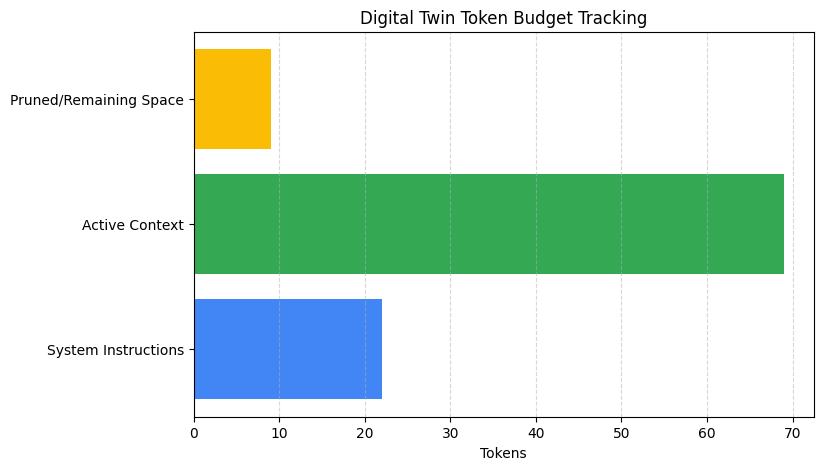

In [10]:
# Demo run of the fully integrated Challenge Project system
twin_ctx = DigitalTwinContextManager(
    system_instruction="You are an AI twin simulating an experienced software developer specializing in algorithms.",
    max_budget=100
)

# Simulating several conversational turns with different lengths
twin_ctx.add_turn("user", "Can you explain the basic implementation of quicksort?")
twin_ctx.add_turn("assistant", "Sure! Quicksort works by choosing a pivot and partitioning elements smaller and larger than it.")
twin_ctx.add_turn("user", "That makes sense. Can you write down a python function doing that quickly?")
twin_ctx.add_turn("assistant", "Yes, here it is: def quicksort(arr): return quicksort([x for x in arr[1:] if x < arr[0]]) + [arr[0]] + quicksort([x for x in arr[1:] if x >= arr[0]]) if arr else []")

print("### Compiled Active Context for LLM Assembly:")
for msg in twin_ctx.get_optimized_context():
    print(f"[{msg['role'].upper()}]: {msg['content']}")

twin_ctx.plot_token_distribution()